In [154]:
import pandas as pd
import os

#folder_path = "checkpoints/checkpints20260416_vnmath192"
folder_path = "."
jsonl_files = [f for f in os.listdir(folder_path) if f.endswith('.jsonl')]

dfs = {}
for file in jsonl_files:
    file_path = os.path.join(folder_path, file)
    dfs[file] = pd.read_json(file_path, lines=True)

In [155]:
# Remove prism-ml models from dfs
dfs = {k: v for k, v in dfs.items() if not k.startswith('checkpoint_prism-ml')}

In [156]:
dfs

{'checkpoint_qwen2.5-7b.jsonl':                      timestamp       model  task_id  run_id  passed  \
 0   2026-04-16 15:59:03.039294  qwen2.5:7b        1       1   False   
 1   2026-04-16 15:59:17.619345  qwen2.5:7b        2       1   False   
 2   2026-04-16 15:59:20.487217  qwen2.5:7b        3       1   False   
 3   2026-04-16 15:59:26.595076  qwen2.5:7b        4       1   False   
 4   2026-04-16 15:59:37.946812  qwen2.5:7b        5       1   False   
 ..                         ...         ...      ...     ...     ...   
 187 2026-04-16 16:26:35.886089  qwen2.5:7b      188       1   False   
 188 2026-04-16 16:26:56.595077  qwen2.5:7b      189       1   False   
 189 2026-04-16 16:27:08.713938  qwen2.5:7b      190       1   False   
 190 2026-04-16 16:27:25.426588  qwen2.5:7b      191       1   False   
 191 2026-04-16 16:27:31.188531  qwen2.5:7b      192       1   False   
 
      tests_passed  tests_total  \
 0               0            7   
 1               0            7  

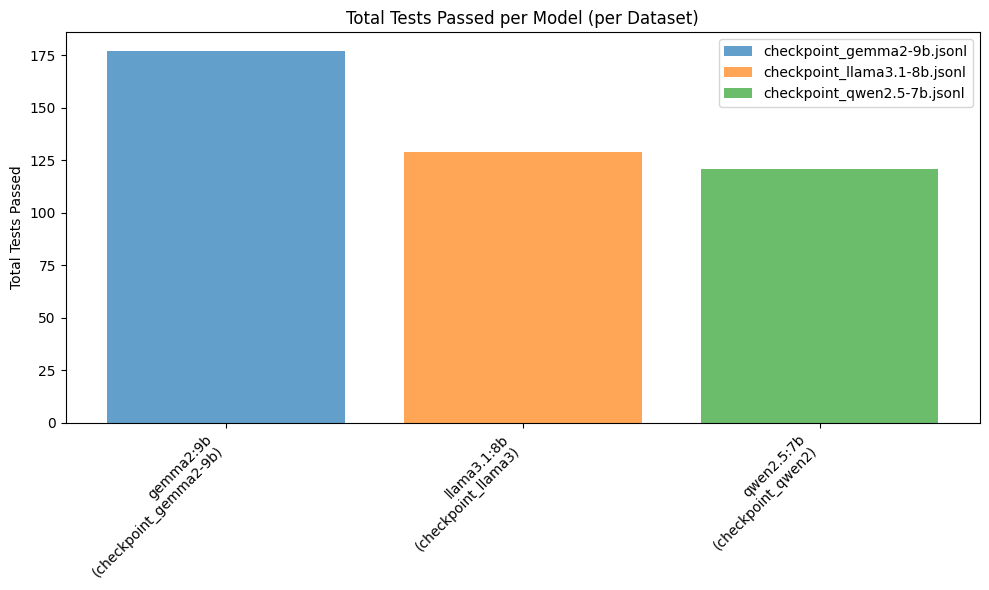

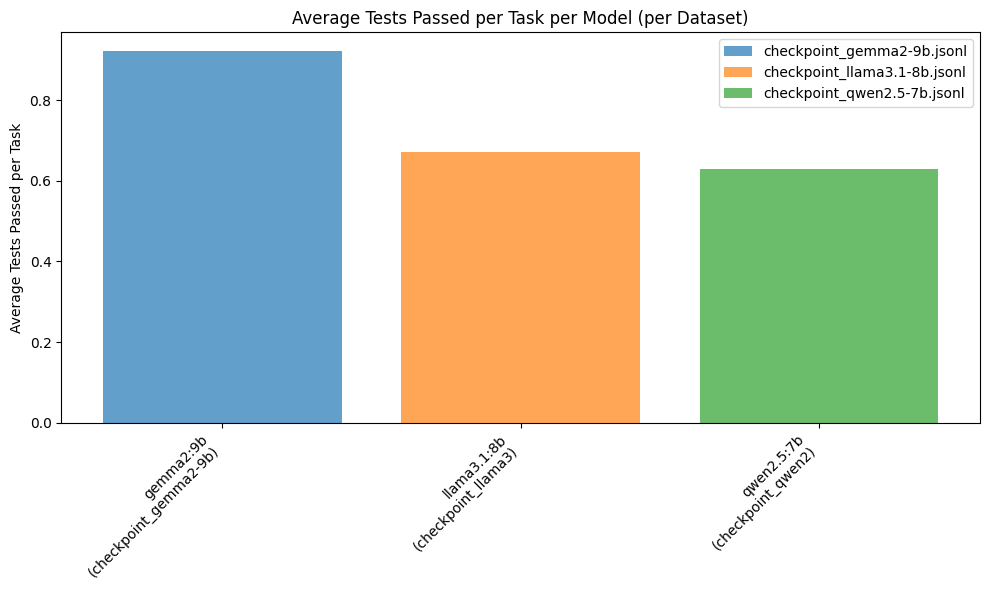

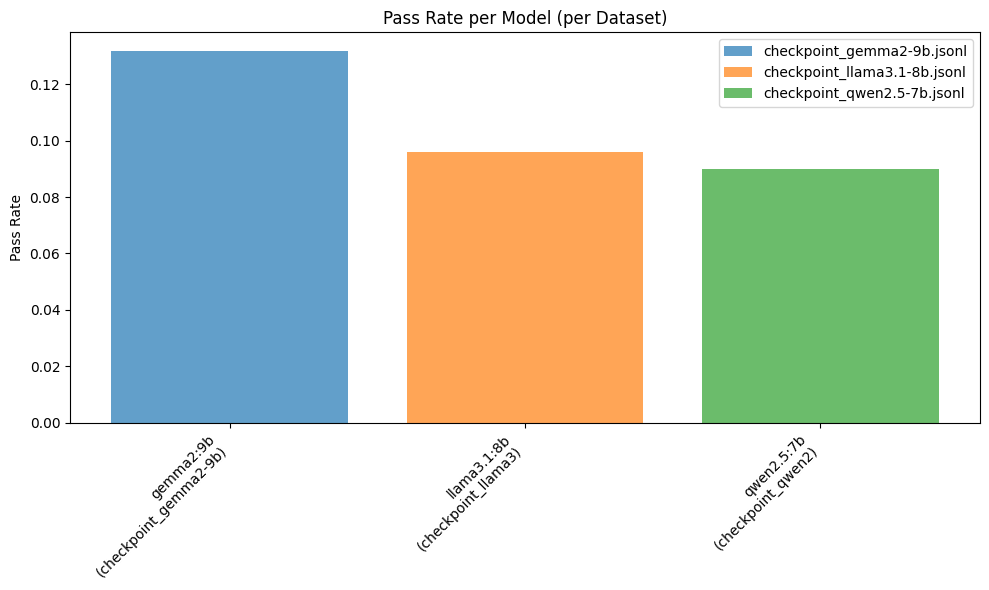

In [157]:
import matplotlib.pyplot as plt

# 1. Aggregate: Calculate total and average tests passed per model across all datasets
model_stats = []
for fname, df in dfs.items():
    if 'model' in df.columns and 'tests_passed' in df.columns and 'tests_total' in df.columns:
        grouped = df.groupby('model').agg(
            total_passed=('tests_passed', 'sum'),
            total_tests=('tests_total', 'sum'),
            avg_passed=('tests_passed', 'mean')
        ).reset_index()
        grouped['dataset'] = fname
        model_stats.append(grouped)
model_stats_df = pd.concat(model_stats, ignore_index=True)

# 2. Plot: Total tests passed per model (across all datasets)
plt.figure(figsize=(10, 6))
for dataset, group in model_stats_df.groupby('dataset'):
    plt.bar(group['model'] + f"\n({dataset.split('.')[0]})", group['total_passed'], label=dataset, alpha=0.7)
plt.ylabel('Total Tests Passed')
plt.title('Total Tests Passed per Model (per Dataset)')
plt.xticks(rotation=45, ha='right')
plt.legend()
plt.tight_layout()
plt.show()

# 3. Plot: Average tests passed per task per model (across all datasets)
plt.figure(figsize=(10, 6))
for dataset, group in model_stats_df.groupby('dataset'):
    plt.bar(group['model'] + f"\n({dataset.split('.')[0]})", group['avg_passed'], label=dataset, alpha=0.7)
plt.ylabel('Average Tests Passed per Task')
plt.title('Average Tests Passed per Task per Model (per Dataset)')
plt.xticks(rotation=45, ha='right')
plt.legend()
plt.tight_layout()
plt.show()

# 4. Plot: Pass rate per model (total_passed / total_tests)
model_stats_df['pass_rate'] = model_stats_df['total_passed'] / model_stats_df['total_tests']
plt.figure(figsize=(10, 6))
for dataset, group in model_stats_df.groupby('dataset'):
    plt.bar(group['model'] + f"\n({dataset.split('.')[0]})", group['pass_rate'], label=dataset, alpha=0.7)
plt.ylabel('Pass Rate')
plt.title('Pass Rate per Model (per Dataset)')
plt.xticks(rotation=45, ha='right')
plt.legend()
plt.tight_layout()
plt.show()

In [158]:
# Create a summary DataFrame with task_id, model, and number of tests passed (tests_passed), "passed", for each dataset
summary_rows = []

for fname, df in dfs.items():
    if {'task_id', 'model', 'tests_passed', 'passed'}.issubset(df.columns):
        summary_rows.append(
            df[['task_id', 'model', 'tests_passed', 'passed']].copy().assign(dataset=fname)
        )

summary_df = pd.concat(summary_rows, ignore_index=True)
summary_df.head()

,task_id,model,tests_passed,passed,dataset
0,1,qwen2.5:7b,0,False,checkpoint_qwen2.5-7b.jsonl
1,2,qwen2.5:7b,0,False,checkpoint_qwen2.5-7b.jsonl
2,3,qwen2.5:7b,0,False,checkpoint_qwen2.5-7b.jsonl
3,4,qwen2.5:7b,0,False,checkpoint_qwen2.5-7b.jsonl
4,5,qwen2.5:7b,0,False,checkpoint_qwen2.5-7b.jsonl


In [159]:
# Pivot summary_df to have models as columns (features), with num_passed as values
pivot_df = summary_df.pivot(index='task_id', columns='model', values='tests_passed').reset_index()

# For each model, create a boolean column indicating if the model passed the test (num_passed > 0)
for model in pivot_df.columns[1:]:
    pivot_df[f'{model}_passed'] = pivot_df[model] == 7

pivot_df.head()

model,task_id,gemma2:9b,llama3.1:8b,qwen2.5:7b,gemma2:9b_passed,llama3.1:8b_passed,qwen2.5:7b_passed
0,1,0,0,0,False,False,False
1,2,0,0,0,False,False,False
2,3,6,0,0,False,False,False
3,4,7,0,0,True,False,False
4,5,0,0,0,False,False,False


In [160]:
# Analyze pivot_df for task difficulty and model performance patterns

# 1. Tasks failed by all models (all *_passed columns are False)
all_passed_cols = [col for col in pivot_df.columns if col.endswith('_passed')]
tasks_failed_by_all = pivot_df.loc[~pivot_df[all_passed_cols].any(axis=1), 'task_id'].tolist()

# 2. Tasks passed by all models (all *_passed columns are True)
tasks_passed_by_all = pivot_df.loc[pivot_df[all_passed_cols].all(axis=1), 'task_id'].tolist()

# 3. Tasks passed by some models but not others
tasks_partial = pivot_df.loc[(pivot_df[all_passed_cols].any(axis=1)) & (~pivot_df[all_passed_cols].all(axis=1)), 'task_id'].tolist()

# 4. For each model, count number of tasks passed
model_pass_counts = {col.replace('_passed', ''): pivot_df[col].sum() for col in all_passed_cols}

# 5. For each task, list which models passed and which failed
task_model_pass = []
for idx, row in pivot_df.iterrows():
    passed_models = [col.replace('_passed', '') for col in all_passed_cols if row[col]]
    failed_models = [col.replace('_passed', '') for col in all_passed_cols if not row[col]]
    task_model_pass.append({
        'task_id': row['task_id'],
        'passed_models': passed_models,
        'failed_models': failed_models
    })

# Print summary
print(f"Tasks failed by all models ({len(tasks_failed_by_all)}): {tasks_failed_by_all}")
print(f"Tasks passed by all models ({len(tasks_passed_by_all)}): {tasks_passed_by_all}")
print(f"Tasks passed by some models but not others ({len(tasks_partial)}): {tasks_partial[:10]}{'...' if len(tasks_partial) > 10 else ''}")
print("\nNumber of tasks passed by each model:")
for model, count in model_pass_counts.items():
    print(f"  {model}: {count}")

# Example: Show first 5 tasks with partial pass/fail
print("\nSample tasks with mixed results (first 5):")
for entry in task_model_pass:
    if entry['task_id'] in tasks_partial:
        print(f"Task {entry['task_id']}: Passed by {entry['passed_models']}, Failed by {entry['failed_models']}")
        if sum([entry['task_id'] in tasks_partial for entry in task_model_pass[:5]]) >= 5:
            break

Tasks failed by all models (164): [1, 2, 3, 5, 6, 7, 8, 9, 13, 14, 15, 16, 17, 18, 20, 21, 22, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 36, 37, 39, 40, 41, 42, 43, 44, 46, 47, 48, 49, 50, 51, 52, 53, 55, 56, 57, 58, 59, 62, 64, 65, 66, 67, 68, 70, 71, 72, 73, 74, 76, 77, 78, 80, 81, 82, 83, 84, 85, 86, 87, 89, 90, 91, 92, 93, 94, 96, 97, 99, 100, 101, 102, 103, 104, 105, 106, 107, 108, 109, 110, 111, 112, 113, 115, 116, 117, 118, 119, 120, 121, 122, 123, 124, 125, 126, 127, 128, 129, 130, 131, 132, 133, 134, 135, 136, 137, 138, 139, 140, 141, 142, 143, 144, 145, 146, 147, 148, 149, 150, 151, 152, 153, 154, 155, 157, 158, 161, 163, 164, 165, 167, 168, 169, 170, 171, 172, 173, 174, 175, 176, 177, 178, 180, 182, 184, 185, 186, 187, 188, 189, 190, 191, 192]
Tasks passed by all models (4): [11, 45, 69, 166]
Tasks passed by some models but not others (24): [4, 10, 12, 19, 23, 35, 38, 54, 60, 61]...

Number of tasks passed by each model:
  gemma2:9b: 17
  llama3.1:8b: 15
  qwen2.5:7b: 13



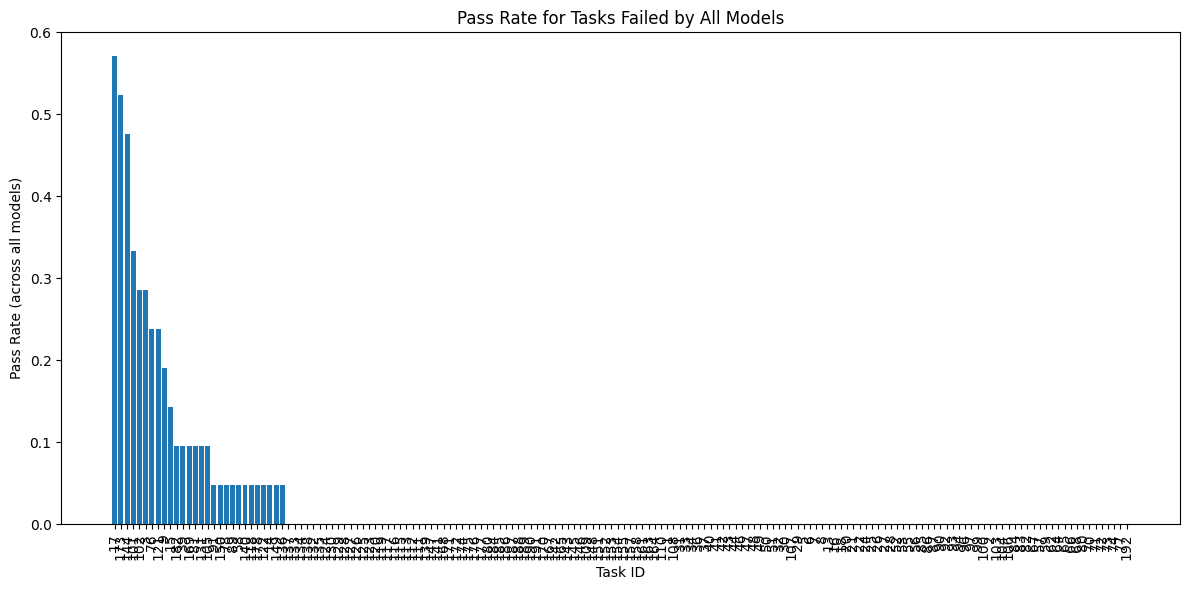

In [161]:
# For tasks failed by all models, calculate the number of tests passed (sum across all models) and total tests
failed_tasks_df = pivot_df[pivot_df['task_id'].isin(tasks_failed_by_all)].copy()

# Sum tests_passed and tests_total for each task across all models
model_names = [col for col in pivot_df.columns if col not in ['task_id'] + all_passed_cols]
failed_tasks_stats = []

for _, row in failed_tasks_df.iterrows():
    task_id = row['task_id']
    # For each model, get tests_passed from summary_df
    task_rows = summary_df[summary_df['task_id'] == task_id]
    total_passed = task_rows['tests_passed'].sum()
    total_tests = task_rows['tests_passed'].count() * 7  # Each model has 7 tests per task
    failed_tasks_stats.append({'task_id': task_id, 'total_passed': total_passed, 'total_tests': total_tests})

failed_tasks_stats_df = pd.DataFrame(failed_tasks_stats)
failed_tasks_stats_df['pass_rate'] = failed_tasks_stats_df['total_passed'] / failed_tasks_stats_df['total_tests']

# Sort by pass_rate descending
failed_tasks_stats_df_sorted = failed_tasks_stats_df.sort_values('pass_rate', ascending=False)

# Visualize
plt.figure(figsize=(12, 6))
plt.bar(failed_tasks_stats_df_sorted['task_id'].astype(str), failed_tasks_stats_df_sorted['pass_rate'])
plt.xlabel('Task ID')
plt.ylabel('Pass Rate (across all models)')
plt.title('Pass Rate for Tasks Failed by All Models')
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

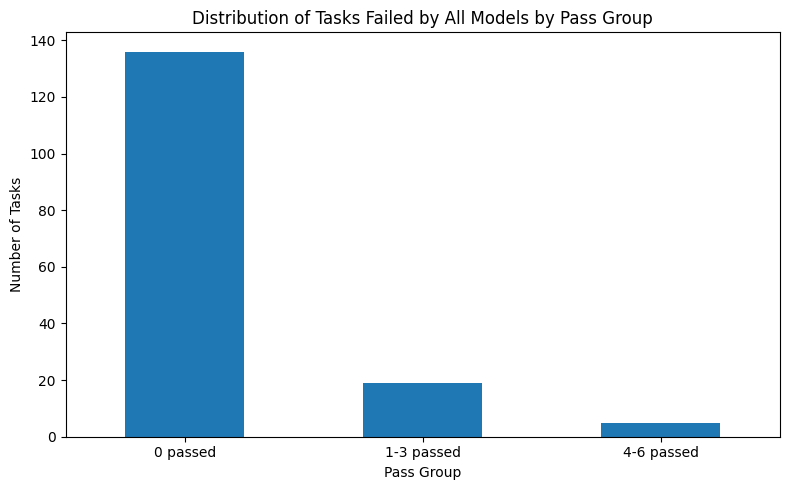

In [162]:
#make failed_tasks_stats_df to 3 groups: 0 passed, 1-3 passed, 4-6 passed
#visualize the distribution of these groups using a bar chart
failed_tasks_stats_df['pass_group'] = pd.cut(failed_tasks_stats_df['total_passed'], bins=[-1, 0, 3, 6], labels=['0 passed', '1-3 passed', '4-6 passed'])
group_counts = failed_tasks_stats_df['pass_group'].value_counts().sort_index()
plt.figure(figsize=(8, 5))
group_counts.plot(kind='bar')
plt.xlabel('Pass Group')
plt.ylabel('Number of Tasks')
plt.title('Distribution of Tasks Failed by All Models by Pass Group')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [163]:
print(group_counts)

pass_group
0 passed      136
1-3 passed     19
4-6 passed      5
Name: count, dtype: int64


In [164]:
# Get task_ids for 1-3 passed and 4-6 passed groups
tasks_1_3_passed = failed_tasks_stats_df.loc[failed_tasks_stats_df['pass_group'] == '1-3 passed', 'task_id'].tolist()
tasks_4_6_passed = failed_tasks_stats_df.loc[failed_tasks_stats_df['pass_group'] == '4-6 passed', 'task_id'].tolist()

# Combine with tasks_partial (Tasks passed by some models but not others)
combined_tasklist = sorted(set(tasks_1_3_passed + tasks_4_6_passed + tasks_partial))
print(f"Combined tasklist ({len(combined_tasklist)} tasks): {combined_tasklist}")

Combined tasklist (48 tasks): [3, 4, 9, 10, 12, 14, 15, 19, 23, 35, 38, 39, 54, 58, 60, 61, 63, 75, 76, 78, 79, 81, 88, 89, 91, 95, 98, 102, 105, 114, 118, 121, 122, 131, 136, 140, 149, 150, 156, 159, 160, 162, 169, 178, 179, 181, 182, 183]


In [165]:
# For each task in combined_tasklist, count how many models passed and total tests passed
task_pass_summary = []

for task_id in combined_tasklist:
    row = pivot_df[pivot_df['task_id'] == task_id].iloc[0]
    # Count how many models passed (i.e., *_passed == True)
    num_models_passed = sum([row[col] for col in all_passed_cols])
    # Total testcases passed (sum across all models)
    total_tests_passed = sum([row[model] for model in model_names])
    task_pass_summary.append({
        'task_id': task_id,
        'num_models_passed': num_models_passed,
        'total_tests_passed': total_tests_passed
    })

combined_task_df = pd.DataFrame(task_pass_summary)
combined_task_df.head()

,task_id,num_models_passed,total_tests_passed
0,3,0,6
1,4,1,7
2,9,0,4
3,10,1,7
4,12,2,14


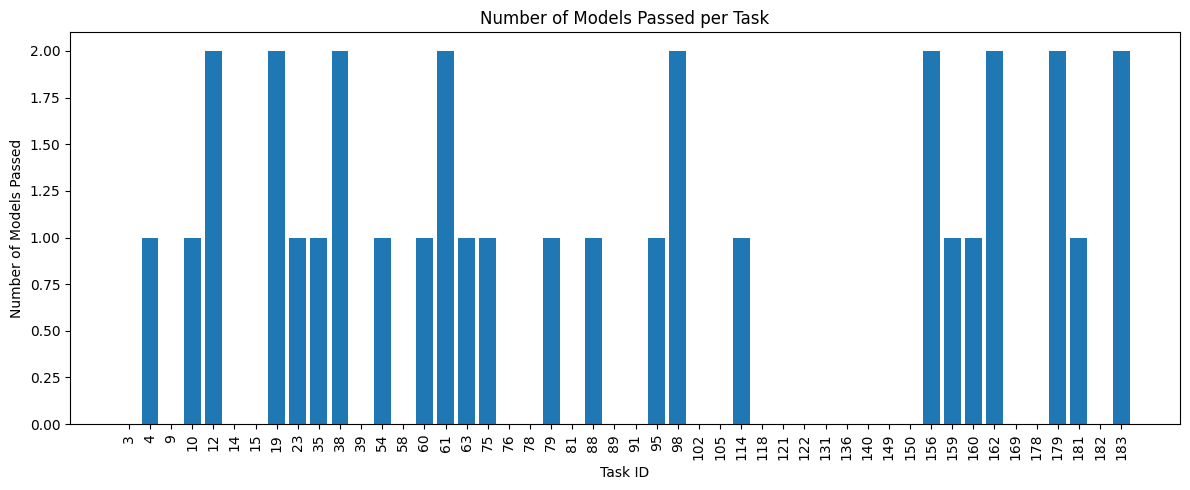

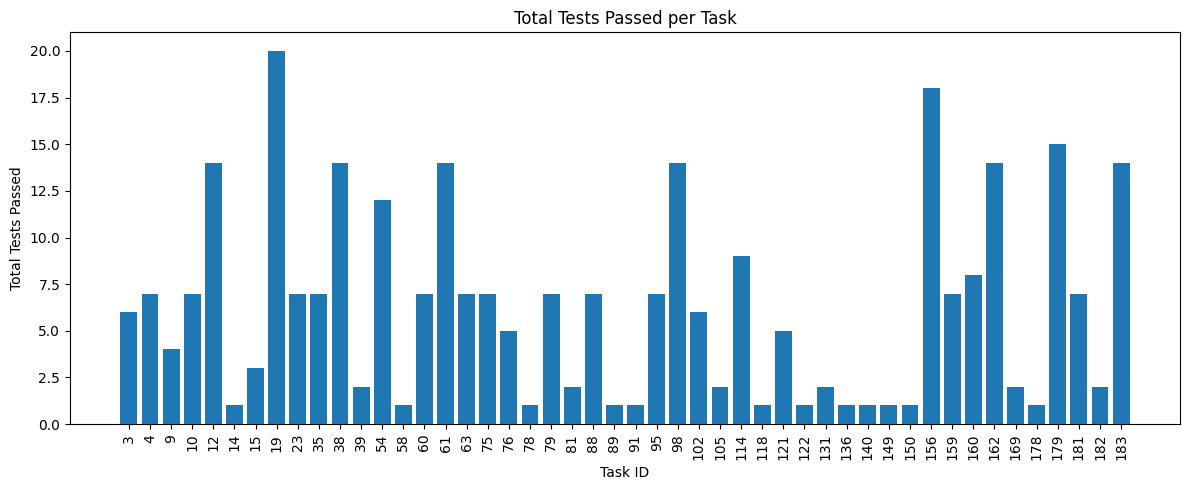

In [166]:
import matplotlib.pyplot as plt

# Bar plot: Number of models passed per task
plt.figure(figsize=(12, 5))
plt.bar(combined_task_df['task_id'].astype(str), combined_task_df['num_models_passed'])
plt.xlabel('Task ID')
plt.ylabel('Number of Models Passed')
plt.title('Number of Models Passed per Task')
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

# Bar plot: Total tests passed per task
plt.figure(figsize=(12, 5))
plt.bar(combined_task_df['task_id'].astype(str), combined_task_df['total_tests_passed'])
plt.xlabel('Task ID')
plt.ylabel('Total Tests Passed')
plt.title('Total Tests Passed per Task')
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

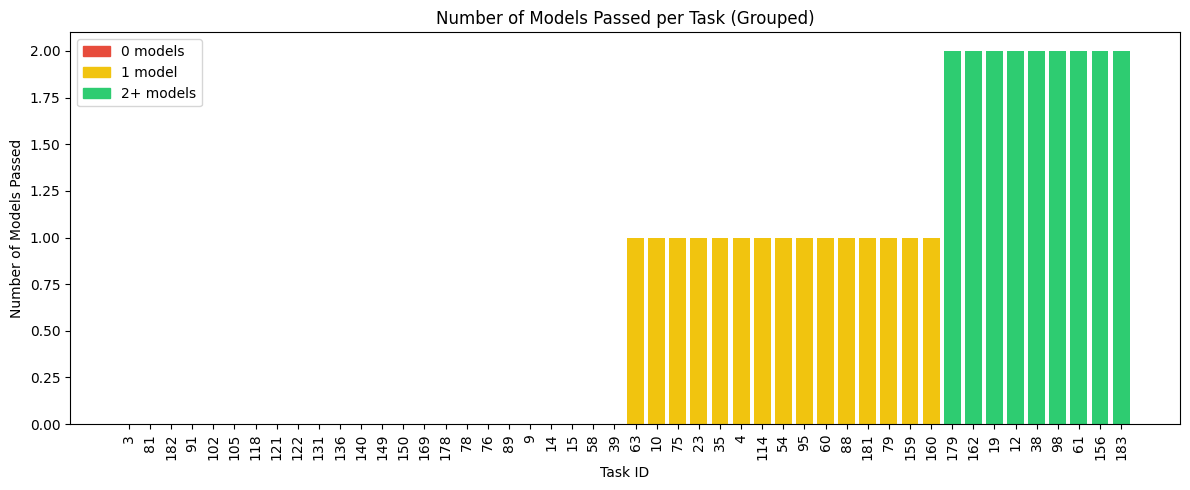

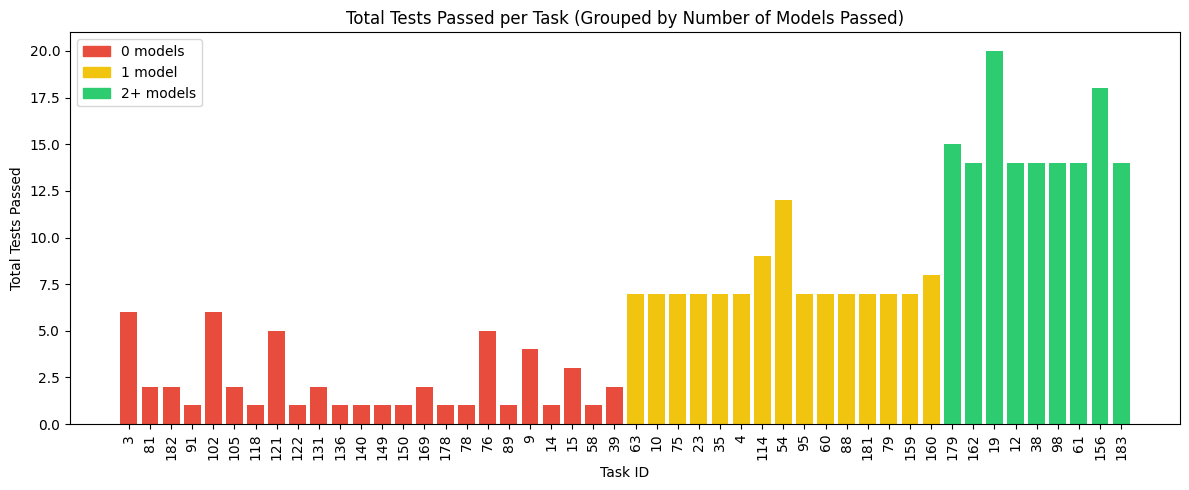

In [167]:
# Sort combined_task_df by num_models_passed
sorted_df = combined_task_df.sort_values('num_models_passed')

# Map number of models passed to color and label
def group_color_label(n):
    if n == 0:
        return '#e74c3c', '0 models'
    elif n == 1:
        return '#f1c40f', '1 model'
    else:
        return '#2ecc71', '2+ models'

colors = sorted_df['num_models_passed'].map(lambda n: group_color_label(n)[0])
group_map = sorted_df['num_models_passed'].map(lambda n: group_color_label(n)[1])

# Bar plot: Number of models passed per task (grouped by color)
plt.figure(figsize=(12, 5))
bars = plt.bar(sorted_df['task_id'].astype(str), sorted_df['num_models_passed'], color=colors)
plt.xlabel('Task ID')
plt.ylabel('Number of Models Passed')
plt.title('Number of Models Passed per Task (Grouped)')
plt.xticks(rotation=90)
# Custom legend
import matplotlib.patches as mpatches
legend_elements = [
    mpatches.Patch(color='#e74c3c', label='0 models'),
    mpatches.Patch(color='#f1c40f', label='1 model'),
    mpatches.Patch(color='#2ecc71', label='2+ models')
]
plt.legend(handles=legend_elements)
plt.tight_layout()
plt.show()

# Bar plot: Total tests passed per task (same color grouping)
plt.figure(figsize=(12, 5))
bars2 = plt.bar(sorted_df['task_id'].astype(str), sorted_df['total_tests_passed'], color=colors)
plt.xlabel('Task ID')
plt.ylabel('Total Tests Passed')
plt.title('Total Tests Passed per Task (Grouped by Number of Models Passed)')
plt.xticks(rotation=90)
plt.legend(handles=legend_elements)
plt.tight_layout()
plt.show()

In [168]:
import json

# Load the full problems file
with open('VNSchoolMathProblems.v0.3.json', 'r', encoding='utf-8') as f:
    all_tasks = json.load(f)

# Filter tasks whose task_id is in combined_tasklist
lite_tasks = [task for task in all_tasks if task.get('task_id') in combined_tasklist]

# Export to new file
with open('VNSchoolMathProblems_lite.v0.4.json', 'w', encoding='utf-8') as f:
    json.dump(lite_tasks, f, ensure_ascii=False, indent=2)

print(f"Exported {len(lite_tasks)} tasks to VNSchoolMathProblems_lite.v0.4.json")

Exported 48 tasks to VNSchoolMathProblems_lite.v0.4.json


In [169]:
import json

# Select 2 tasks from tasks_failed_by_all that are not already in lite_tasks
existing_task_ids = {task['task_id'] for task in lite_tasks}
to_add_ids = [tid for tid in tasks_failed_by_all if tid not in existing_task_ids][:2]

# Load all_tasks if not already loaded (should be available from previous cells)
# with open('VNSchoolMathProblems.v0.3.json', 'r', encoding='utf-8') as f:
#     all_tasks = json.load(f)

# Find the corresponding task dicts
to_add_tasks = [task for task in all_tasks if task.get('task_id') in to_add_ids]

# Add to lite_tasks
lite_tasks_extended = lite_tasks + to_add_tasks

# Save to new file
with open('VNSchoolMathProblems_lite.v0.5.json', 'w', encoding='utf-8') as f:
    json.dump(lite_tasks_extended, f, ensure_ascii=False, indent=2)

print(f"Added {len(to_add_tasks)} tasks. Exported {len(lite_tasks_extended)} tasks to VNSchoolMathProblems_lite.v0.5.json.")

Added 2 tasks. Exported 50 tasks to VNSchoolMathProblems_lite.v0.5.json.


In [170]:
# Add 'difficulty' to lite_tasks_extended using num_models_passed from sorted_df
# 0: hard, 1: medium, 2: easy

# Build a mapping from task_id to num_models_passed
task_id_to_total_tests_passed = dict(zip(sorted_df['task_id'], sorted_df['num_models_passed']))

def get_difficulty_by_tests_passed(num_models_passed):
    if num_models_passed == 0 or num_models_passed == None:
        return 'hard'
    elif num_models_passed == 1:
        return 'medium'
    else:
        return 'easy'

lite_tasks_extended_with_difficulty = []
for task in lite_tasks_extended:
    total_tests = task_id_to_total_tests_passed.get(task['task_id'], None)
    task_copy = task.copy()
    task_copy['difficulty'] = get_difficulty_by_tests_passed(total_tests)
    lite_tasks_extended_with_difficulty.append(task_copy)

# Save to new file
with open('VNSchoolMathProblems_lite.v0.6.difficulty.json', 'w', encoding='utf-8') as f:
    json.dump(lite_tasks_extended_with_difficulty, f, ensure_ascii=False, indent=2)

print(f"Exported {len(lite_tasks_extended_with_difficulty)} tasks to VNSchoolMathProblems_lite.v0.6.difficulty.json with difficulty field.")

Exported 50 tasks to VNSchoolMathProblems_lite.v0.6.difficulty.json with difficulty field.


In [171]:
import json


# Reindex task_id in lite_tasks_extended_with_difficulty to be consecutive starting from 1
# before reindexing, save the current task_id as old_id in the task dict

reindexed_tasks = []
for new_id, task in enumerate(lite_tasks_extended_with_difficulty, start=1):
    task_copy = task.copy()
    task_copy['old_id'] = task['task_id']
    task_copy['task_id'] = new_id
    reindexed_tasks.append(task_copy)

# Save to new file
with open('VNSchoolMathProblems_lite.v0.7.json', 'w', encoding='utf-8') as f:
    json.dump(reindexed_tasks, f, ensure_ascii=False, indent=2)

print(f"Exported {len(reindexed_tasks)} tasks to VNSchoolMathProblems_lite.v0.7.json with reindexed task_id.")

Exported 50 tasks to VNSchoolMathProblems_lite.v0.7.json with reindexed task_id.


In [172]:
from collections import Counter

# Count number of tasks per difficulty in reindexed_tasks_v07
difficulty_counts = Counter(task.get('difficulty', None) for task in reindexed_tasks)
print(difficulty_counts)

Counter({'hard': 26, 'medium': 15, 'easy': 9})
